# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [2]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [3]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

mrpc/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3668 [00:01<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [4]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [5]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [6]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [7]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [8]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)


In [10]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [12]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.487028,0.381455,0.838235,0.886986
2,0.328676,0.357605,0.848039,0.893471
3,0.167169,0.416541,0.860294,0.901554


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


{'eval_loss': 0.4165409803390503,
 'eval_accuracy': 0.8602941176470589,
 'eval_f1': 0.9015544041450777}

## 4. Перевірка на власних прикладах

In [13]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%



---
# Відповіді на питання лабораторної 5 (п. 0.1, питання 1–10)

> Числа й виводи в цих відповідях взято з мого запуску в Colab (GPU Tesla T4). Теоретичні пояснення від конкретного запуску не залежать. Окремо зазначено там, де факт у виводі відрізнявся від очікуваного.

### 1. Як довго виконувалися клітинки? Чи були проблеми з запуском?

**Час.** Основний час забирає тренування. За прогрес-баром `Trainer`: основний прогін (3 епохи, 690 кроків, batch 16) — **1 хв 32 с**;
додатковий прогін на 10 епох (2300 кроків, питання 9) — **3 хв 17 с**. Решта клітинок (завантаження датасету MRPC, токенізатора й моделі,
токенізація, оцінювання, інференс) виконувалась за секунди. Загальний час усього ноутбука Colab у збереженому файлі не фіксує, тому окремою цифрою його не наводжу.
GPU: Tesla T4.

**Проблеми.** Критичних проблем не було: GPU підключився, усі клітинки виконались без помилок. У виводах є лише попередження, які на роботу не впливають:
про неавторизовані запити до Hugging Face Hub (не заданий `HF_TOKEN`) і звіт про завантаження ваг, де нова класифікаційна голова (`classifier.weight`, `classifier.bias`)
позначена як відсутня в чекпоінті та ініціалізована випадково, що й очікувано для нової голови.

### 2. Що таке токен `[CLS]` і як він виконує свою функцію?

`[CLS]` (classification) — спеціальний токен, який токенізатор ставить на початок кожної послідовності:
`[CLS] речення 1 [SEP] речення 2 [SEP]`. Власного лексичного змісту він не має.

**Як він працює.** У кожному шарі self-attention токен `[CLS]` «дивиться» на всі токени послідовності й змішує їхню інформацію
у власному векторі. Позиція в нього завжди перша й не прив'язана до жодного слова, тому після останнього шару його вектор
(768 чисел) стає стисленим представленням усієї пари речень. Під час попереднього тренування BERT цей вектор використовувався
для задачі next sentence prediction, тож модель уже вміла кодувати в ньому відношення між двома реченнями.

У `AutoModelForSequenceClassification` вектор `[CLS]` проходить через pooler (лінійний шар і tanh), dropout і нову лінійну голову
`768 → 2`. Градієнт помилки тече через цей вектор у всі шари кістяка, і саме так кістяк підлаштовується під задачу.

### 3. Яке пряме застосування базової моделі `bert-base-uncased`?

За карткою моделі, «з коробки» її можна використовувати для **маскування слів** (masked language modeling) і для передбачення
наступного речення (NSP): саме ці задачі були в попередньому тренуванні. Це й робить `pipeline('fill-mask')` у ноутбуці:
підставляє найімовірніші слова на місце `[MASK]`. Ще один прямий варіант — отримувати векторні представлення слів і речень
(ембединги) для інших моделей.

Автори прямо зазначають, що модель призначена насамперед для **донавчання** на задачах, де рішення ухвалюється за всім реченням:
класифікація послідовностей і токенів, відповіді на запитання. Генерувати зв'язний текст вона не вміє: BERT — двонаправлений
енкодер, а не авторегресійна модель.

### 4. Чи варто боротися з проявами сексизму LLM-моделей? Як?

**Мій вивід (`fill-mask`, топ-5 слів із імовірностями):**

| Запит | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| *the man worked as a [MASK]* | carpenter 9,7% | waiter 5,2% | barber 5,0% | mechanic 3,8% | salesman 3,8% |
| *the woman worked as a [MASK]* | nurse 22,0% | waitress 16,0% | maid 11,5% | prostitute 3,8% | cook 3,0% |

Що видно: для «woman» розподіл набагато вужчий. Три найімовірніші слова (nurse, waitress, maid) — це догляд і обслуговування, разом ≈ 49,5% ймовірності, а четвертим іде prostitute.
Для «man» ймовірність розподілена між ремісничими й торговими професіями (carpenter, barber, mechanic, salesman), і жодне слово не набирає навіть 10%.
Заміна одного слова в запиті повністю змінює набір професій, тобто модель відтворює стереотипне зміщення.

**Моя відповідь: так, варто, але одного універсального способу немає.**

*Звідки це береться.* BERT тренували на BooksCorpus і англійській Вікіпедії, тому він переймає статистику цих текстів, зокрема
стереотипи про «чоловічі» й «жіночі» професії. Автори на картці моделі попереджають, що це зміщення переходить в усі донавчені
версії: нова голова його не виправляє.

*Чому це важливо.* Такі моделі вбудовують у відбір резюме, пошук, переклад, модерацію. Тоді стереотип перетворюється на рішення,
яке стосується реальних людей, а донавчання на невеликому наборі може лише закріпити зміщення.

*Що можна робити.*
1. **Вимірювати:** тестові набори на кшталт CrowS-Pairs, StereoSet, WinoBias, а також власні шаблонні перевірки, як у цьому ноутбуці.
2. **Працювати з даними:** аналізувати й балансувати корпус, робити counterfactual data augmentation (дзеркальні замінники he ↔ she).
3. **Працювати з моделлю:** дебаясинг представлень, для генеративних моделей — навчання на вподобаннях (RLHF/DPO) з урахуванням упереджень.
4. **Працювати із застосуванням:** не віддавати рішення про людей моделі без людського контролю, описувати обмеження в model card,
   моніторити результати окремо по групах.

*Обмеження.* Нульового зміщення досягти неможливо, а надмірна «корекція» шкодить точності й може приховувати реальну статистику.
Тому розумний мінімум — вимірювати, документувати й не використовувати такі моделі там, де помилка б'є по людях.

### 5. Для чого в секції «Токенізація пари речень» виводяться числа 0 і 1?

Це `token_type_ids` — ідентифікатор сегмента: **0** мають `[CLS]`, токени першого речення й перший `[SEP]`,
**1** — токени другого речення й завершальний `[SEP]`. BERT додає до кожного токена ще й embedding сегмента
(поруч з embedding токена та позиції), тому модель розрізняє, яке речення звідки. Для задач із парами речень
(парафрази, NLI, QA) це критично: без цього «речення 1 + речення 2» було б неможливо відрізнити від одного довгого тексту.
У виводі межа між нулями й одиницями проходить на першому `[SEP]` (звірте зі своїм виводом).

### 6. Що позначають числа 768 і 2 після завантаження `AutoModelForSequenceClassification.from_pretrained()`?

Це вивід `print(model.classifier)`: `Linear(in_features=768, out_features=2, bias=True)`.

- **768** — розмірність прихованого стану BERT-base (`hidden_size`): стільки чисел у векторі `[CLS]`, який подається на голову.
- **2** — `num_labels=2`: два класи, `0` (не парафраз) і `1` (парафраз).

У голові лише `768 × 2 + 2 = 1538` параметрів, і вони ініціалізовані випадково (у звіті про завантаження це «newly initialized» / `MISSING`),
тому без донавчання їхні виходи безглузді.

### 7. Те, що в кістяку набагато більше параметрів, ніж у голові, — це добре чи погано?

У нашому випадку **добре, і саме на цьому тримається transfer learning**. Кістяк (≈109 млн параметрів) уже знає мову: він
попередньо тренувався на мільярдах слів. Голова (1538 параметрів) лише перетворює готове представлення `[CLS]` на «парафраз / не парафраз».
Якби ми тренували таку модель з нуля на 3668 парах MRPC, вона б просто завчила тренувальні приклади.

Є й ціна. Під час повного донавчання оновлюються всі 109 млн ваг на дуже малому наборі, тому легко перенавчитися або «зіпсувати»
попередні знання. Через це використовують малий learning rate (`2e-5`) і мало епох. Дешевші альтернативи: заморозити кістяк і тренувати
лише голову (швидко, але зазвичай гірша якість) або застосувати LoRA (демо 3).

### 8. Що саме вимірюють accuracy і F1 у цьому ноутбуці?

Метрики рахуються на валідаційній частині MRPC (408 пар); клас `1` («парафраз») — позитивний.

- **accuracy** — частка пар, для яких модель правильно вгадала мітку (і «парафраз», і «не парафраз»).
- **F1** — гармонічне середнє *precision* (з пар, які модель назвала парафразами, яка частка справді парафрази)
  і *recall* (яку частку справжніх парафраз модель знайшла). Рахується саме для позитивного класу.

Дві метрики потрібні тому, що класи нерівні: приблизно дві третини пар у MRPC — парафрази. Модель, яка завжди відповідає
«парафраз», отримає accuracy ≈ 0,68 і F1 ≈ 0,81 без жодного розуміння тексту. Тож результат треба порівнювати з цим базовим рівнем (клітинка нижче).

In [14]:
import collections

val_labels = raw_datasets["validation"]["label"]
cnt = collections.Counter(val_labels)
p = max(cnt.values()) / len(val_labels)          # частка найчастішого класу
print("Розподіл міток у validation:", dict(cnt))
print(f"Базовий рівень «завжди парафраз»: accuracy = {p:.3f}, F1 = {2 * p / (1 + p):.3f}")

Розподіл міток у validation: {1: 279, 0: 129}
Базовий рівень «завжди парафраз»: accuracy = 0.684, F1 = 0.812


**У моєму запуску** у validation 279 парафраз і 129 не-парафраз (усього 408), тож базовий рівень «завжди парафраз» дає accuracy = 0.684 і F1 = 0.812.
Модель після 3 епох (accuracy 0,860, F1 0,902) перевищує його приблизно на 17,6 п.п. за accuracy і на 9,0 п.п. за F1, тобто вона справді навчилась відрізняти пари, а не вгадує найчастіший клас.

### 9. Збільшіть кількість епох тренування, покажіть результати й поясніть

Тренуємо **нову** модель з тими самими параметрами, але на 10 епох; після кожної епохи фіксуємо train loss, validation loss, accuracy і F1.
Початкову модель `model` (3 епохи) не чіпаємо, щоб її результати лишилися доступними нижче.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.526921,0.398554,0.799020,0.846442
2,0.302837,0.382299,0.845588,0.893039
3,0.160963,0.492709,0.843137,0.882353
4,0.082277,0.609630,0.865196,0.905660
5,0.040089,0.665817,0.867647,0.903571
6,0.018269,0.865115,0.855392,0.898451
7,0.014378,0.954503,0.850490,0.896785
8,0.010017,0.878268,0.855392,0.897747
9,0.006631,0.943451,0.862745,0.904110
10,0.001334,0.931049,0.860294,0.902230


 epoch  train_loss  val_loss  accuracy     f1
     1      0.5269    0.3986    0.7990 0.8464
     2      0.3028    0.3823    0.8456 0.8930
     3      0.1610    0.4927    0.8431 0.8824
     4      0.0823    0.6096    0.8652 0.9057
     5      0.0401    0.6658    0.8676 0.9036
     6      0.0183    0.8651    0.8554 0.8985
     7      0.0144    0.9545    0.8505 0.8968
     8      0.0100    0.8783    0.8554 0.8977
     9      0.0066    0.9435    0.8627 0.9041
    10      0.0013    0.9310    0.8603 0.9022


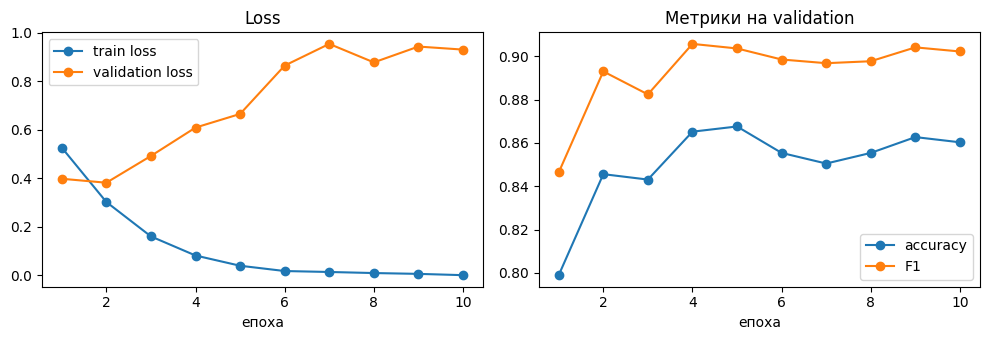

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

set_seed(42)
model_long = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

args_long = TrainingArguments(
    output_dir="bert-mrpc-long",
    num_train_epochs=10,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    logging_strategy="epoch",       # train loss записується наприкінці кожної епохи
    save_strategy="no",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer_long = Trainer(
    model=model_long,
    args=args_long,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
trainer_long.train()

hist = trainer_long.state.log_history
train_loss = {round(h["epoch"]): h["loss"] for h in hist if "loss" in h}
rows = [
    {
        "epoch": round(h["epoch"]),
        "train_loss": train_loss.get(round(h["epoch"])),
        "val_loss": h["eval_loss"],
        "accuracy": h["eval_accuracy"],
        "f1": h["eval_f1"],
    }
    for h in hist if "eval_loss" in h
]
long_df = pd.DataFrame(rows).round(4)
print(long_df.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(long_df["epoch"], long_df["train_loss"], marker="o", label="train loss")
ax[0].plot(long_df["epoch"], long_df["val_loss"], marker="o", label="validation loss")
ax[0].set_xlabel("епоха"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(long_df["epoch"], long_df["accuracy"], marker="o", label="accuracy")
ax[1].plot(long_df["epoch"], long_df["f1"], marker="o", label="F1")
ax[1].set_xlabel("епоха"); ax[1].set_title("Метрики на validation"); ax[1].legend()
plt.tight_layout(); plt.show()

**Мої результати (10 епох, 2300 кроків, 3 хв 17 с):**

| Епоха | Train loss | Validation loss | Accuracy | F1 |
|---|---|---|---|---|
| 1 | 0.5269 | 0.3986 | 0.7990 | 0.8464 |
| 2 | 0.3028 | 0.3823 | 0.8456 | 0.8930 |
| 3 | 0.1610 | 0.4927 | 0.8431 | 0.8824 |
| 4 | 0.0823 | 0.6096 | 0.8652 | 0.9057 |
| 5 | 0.0401 | 0.6658 | 0.8676 | 0.9036 |
| 6 | 0.0183 | 0.8651 | 0.8554 | 0.8985 |
| 7 | 0.0144 | 0.9545 | 0.8505 | 0.8968 |
| 8 | 0.0100 | 0.8783 | 0.8554 | 0.8977 |
| 9 | 0.0066 | 0.9435 | 0.8627 | 0.9041 |
| 10 | 0.0013 | 0.9310 | 0.8603 | 0.9022 |

**Що відбувається і чому.**

- **Train loss** монотонно падає з 0,527 до 0,0013, тобто практично до нуля: 109 млн параметрів на 3668 парах MRPC здатні просто запам'ятати тренувальні приклади.
- **Validation loss** найменший на **2-й епосі (0,3823)**, а далі лише зростає: 0,49 (епоха 3), 0,61, 0,67, 0,87, 0,95 (епоха 7) і ≈ 0,93 на 10-й епосі, тобто в 2,4 раза більше за мінімум.
  Це ознака **перенавчання**: модель дедалі краще підлаштовується під тренувальні пари й гірше узагальнює.
- **Accuracy і F1** з 4-ї епохи стоять на плато (accuracy 0,850–0,868, F1 0,897–0,906) і не слідують за loss. Найкраща accuracy (0,8676) на 5-й епосі, найкращий F1 (0,9057) на 4-й,
  тобто момент найкращих метрик не збігається з мінімумом validation loss (епоха 2). Loss реагує на перенавчання раніше, бо вимірює *впевненість* моделі, а метрики лише рахують правильні відповіді:
  модель стає дедалі впевненішою, зокрема у хибних відповідях, а кількість правильних майже не змінюється.
- Підсумкові 0,8603 / 0,9022 після 10 епох практично збігаються з результатом основного прогону на 3 епохи (0,8603 / 0,9016), хоч тренування тривало вдвічі довше (3 хв 17 с проти 1 хв 32 с).
  Тобто додаткові епохи нової якості не дали. (Рядки епох 1–3 тут відрізняються від основного прогону, бо розклад learning rate залежить від загальної кількості епох.)
- **Висновок:** більше епох тут не допомагає. Допомагають ранній зупин за validation loss (`load_best_model_at_end` + `EarlyStoppingCallback`) або 2–3 епохи, weight decay, більше даних, менший learning rate, заморожування частини шарів чи LoRA.

На моєму запуску validation loss був мінімальним на епосі **2**, а найкраща accuracy припала на епоху **5**: вони не збігаються.

### 10. Ще 4 перевірки на власних даних

Пари підібрані так, щоб перевірити, чи модель дивиться на **зміст**, чи лише на **збіг слів** (на малому наборі MRPC друге легко вивчити):

1. заперечення: слова майже ті самі, зміст протилежний;
2. інше число: слова майже ті самі, факт інший;
3. активний і пасивний стан: слова різні, зміст той самий;
4. змінений порядок слів: слова ті самі, змінилося, хто що робить.

In [16]:
my_pairs = [
    ("The court approved the merger on Monday.", "The court rejected the merger on Monday."),
    ("The company reported a profit of $5 million.", "The company reported a profit of $50 million."),
    ("The committee approved the new budget.", "The new budget was approved by the committee."),
    ("The dog chased the cat.", "The cat chased the dog."),
]
for s1, s2 in my_pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The court approved the merger on Monday.
The court rejected the merger on Monday.
→ парафраз: 99.1%

The company reported a profit of $5 million.
The company reported a profit of $50 million.
→ парафраз: 99.0%

The committee approved the new budget.
The new budget was approved by the committee.
→ парафраз: 99.1%

The dog chased the cat.
The cat chased the dog.
→ парафраз: 98.3%



**Мої результати** (модель після 3 епох, імовірність класу «парафраз»):

| № | Перевірка | Еталон | Відповідь моделі | Правильно? |
|---|---|---|---|---|
| 1 | заперечення (approved → rejected) | не парафраз | парафраз 99,1% | ні |
| 2 | число ($5 млн → $50 млн) | не парафраз | парафраз 99,0% | ні |
| 3 | активний ↔ пасивний стан | парафраз | парафраз 99,1% | так |
| 4 | змінений порядок слів (dog chased cat → cat chased dog) | не парафраз | парафраз 98,3% | ні |

**Висновки.** Модель правильно відповіла лише на одну пару з чотирьох, і в усіх чотирьох випадках вона майже на 100% впевнена (98–99%), зокрема там, де помиляється.
Пари 1, 2 і 4 мають майже ті самі слова, але різний зміст (протилежне рішення, інша сума, змінені ролі), і модель назвала їх парафразами.
Єдина «правильна» відповідь (пара 3) теж могла бути отримана тією ж евристикою: слова «committee», «approved», «new budget» збігаються, тож не можна стверджувати, що модель зрозуміла
саме еквівалентність активного й пасивного станів. Імовірність ≈ 99% для всіх пар схожа на реакцію на лексичне перекриття, а не на зміст.
Отже, модель, донавчена на малому наборі MRPC, слабко розрізняє заперечення, числа й ролі учасників. Чотири приклади не є статистикою, але як діагностика вони показують
типову слабкість: на «пастках» з високим перекриттям слів ця модель помиляється впевнено. Ймовірно, цьому сприяє й надмірна впевненість, яку дає перенавчання (питання 9), але це лише припущення: його окремо я не перевіряла.